## **Phase 2: Diagnostic Classification (Notebook 2)**
Goal: Train a robust classifier, evaluate it thoroughly, and save it.

In [ ]:
!pip install tensorflow

In [ ]:
# --- IMPORTS ---
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Dense, Flatten, Dropout, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.utils import to_categorical

In [ ]:
# --- 1. SET GLOBAL PARAMETERS ---
# This is the most crucial step to avoid errors and ensure reproducibility.
DATA_DIR = "/content/drive/MyDrive/BreastCancerProject/data/processed" # Directory where we saved our NPY files
MODEL_DIR = "/content/drive/MyDrive/BreastCancerProject/models"
RESULTS_DIR = "/content/drive/MyDrive/BreastCancerProject/results/figures"

# Model & Training Hyperparameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 16  # <- DEFINED HERE. Use a smaller batch size if you have memory issues.
NUM_EPOCHS_PHASE1 = 40
NUM_EPOCHS_PHASE2 = 20
LEARNING_RATE_PHASE1 = 1e-3
LEARNING_RATE_PHASE2 = 1e-5
SEED = 42

# Class Map (Must match what was used in Notebook 1)
CLASS_MAP = {'Normal': 0, 'Benign': 1, 'InSitu': 2, 'Invasive': 3}
CLASS_NAMES = list(CLASS_MAP.keys())

# Set random seeds for reproducibility
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
# --- 2. LOAD PREPROCESSED DATA ---
print("Loading preprocessed data...")
try:
    X_train = np.load(os.path.join(DATA_DIR, 'X_train.npy'))
    X_test = np.load(os.path.join(DATA_DIR, 'X_test.npy'))
    y_train_cat = np.load(os.path.join(DATA_DIR, 'y_train_cat.npy'))
    y_test_cat = np.load(os.path.join(DATA_DIR, 'y_test_cat.npy'))
    print("✔️ Data loaded successfully!")
    print(f"Training set: {X_train.shape}, {y_train_cat.shape}")
    print(f"Test set: {X_test.shape}, {y_test_cat.shape}")
except FileNotFoundError as e:
    print(f"❌ Error: {e}. Please run Notebook 1 first to generate the processed data.")
    # If you want to run this cell anyway, you can load the raw data here as a fallback.
    # raise e # Uncomment this to stop the script if the files aren't found.

Loading preprocessed data...
✔️ Data loaded successfully!
Training set: (320, 224, 224, 3), (320, 4)
Test set: (80, 224, 224, 3), (80, 4)


In [ ]:
# --- 3. DATA AUGMENTATION ---
# Use milder augmentation for histology images to avoid distorting key features
print("Setting up data augmentation...")
train_datagen = ImageDataGenerator(
    rotation_range=10,       # Mild rotation
    width_shift_range=0.1,   # Mild horizontal shift
    height_shift_range=0.1,  # Mild vertical shift
    shear_range=0.1,         # Mild shear
    zoom_range=0.1,          # Mild zoom
    horizontal_flip=True,
    fill_mode='nearest'
)
train_datagen.fit(X_train)
print("✔️ Data augmentation generator ready.")

Setting up data augmentation...
✔️ Data augmentation generator ready.


In [ ]:
# --- 4. BUILD THE VGG16 MODEL ---
print("Building the VGG16 model...")
base_model = VGG16(weights='imagenet', include_top=False, input_tensor=Input(shape=(*IMG_SIZE, 3)))

# Freeze the base model layers initially
base_model.trainable = False

# Add custom head for our 4-class problem
x = base_model.output
x = Flatten()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x) # Dropout for regularization
predictions = Dense(4, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

# Compile the model
model.compile(optimizer=Adam(learning_rate=LEARNING_RATE_PHASE1),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary() # Print model architecture to confirm
print("✔️ Model built and compiled.")

# --- 5. SET UP CALLBACKS ---
# Create directories if they don't exist
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Callbacks: Save the best model and stop early if needed
checkpoint_cb = ModelCheckpoint(
    filepath=os.path.join(MODEL_DIR, 'classifier_phase1_best.h5'),
    monitor='val_accuracy',
    mode='max',
    save_best_only=True,
    verbose=1
)

early_stop_cb = EarlyStopping(
    monitor='val_loss',
    patience=10, # Increased patience
    restore_best_weights=True,
    verbose=1
)

Building the VGG16 model...
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,138,500 (80.64 MB)

 Trainable params: 6,423,812 (24.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

✔️ Model built and compiled.


In [ ]:
# --- 6. TRAINING PHASE 1: FEATURE EXTRACTION ---
print("\n" + "="*50)
print("STARTING TRAINING PHASE 1: FEATURE EXTRACTION")
print("="*50)

history_phase1 = model.fit(
    train_datagen.flow(X_train, y_train_cat, batch_size=BATCH_SIZE, seed=SEED),
    steps_per_epoch=len(X_train) // BATCH_SIZE,
    epochs=NUM_EPOCHS_PHASE1,
    validation_data=(X_test, y_test_cat),
    callbacks=[checkpoint_cb, early_stop_cb],
    verbose=1
)


STARTING TRAINING PHASE 1: FEATURE EXTRACTION


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.3582 - loss: 44.8661
Epoch 1: val_accuracy improved from -inf to 0.42500, saving model to /content/drive/MyDrive/BreastCancerProject/models/classifier_phase1_best.h5


20/20 ━━━━━━━━━━━━━━━━━━━━ 273s 14s/step - accuracy: 0.3599 - loss: 44.6875 - val_accuracy: 0.4250 - val_loss: 21.9705
Epoch 2/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.5536 - loss: 17.7674
Epoch 2: val_accuracy improved from 0.42500 to 0.51250, saving model to /content/drive/MyDrive/BreastCancerProject/models/classifier_phase1_best.h5


20/20 ━━━━━━━━━━━━━━━━━━━━ 312s 13s/step - accuracy: 0.5528 - loss: 17.6799 - val_accuracy: 0.5125 - val_loss: 7.2329
Epoch 3/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.5791 - loss: 5.4945
Epoch 3: val_accuracy improved from 0.51250 to 0.70000, saving model to /content/drive/MyDrive/BreastCancerProject/models/classifier_phase1_best.h5


20/20 ━━━━━━━━━━━━━━━━━━━━ 263s 13s/step - accuracy: 0.5796 - loss: 5.4303 - val_accuracy: 0.7000 - val_loss: 1.1176
Epoch 4/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.5084 - loss: 1.6536
Epoch 4: val_accuracy did not improve from 0.70000
20/20 ━━━━━━━━━━━━━━━━━━━━ 278s 11s/step - accuracy: 0.5071 - loss: 1.6509 - val_accuracy: 0.5750 - val_loss: 0.9323
Epoch 5/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.5278 - loss: 1.3084
Epoch 5: val_accuracy did not improve from 0.70000
20/20 ━━━━━━━━━━━━━━━━━━━━ 257s 13s/step - accuracy: 0.5260 - loss: 1.3076 - val_accuracy: 0.5875 - val_loss: 1.0144
Epoch 6/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.5163 - loss: 1.2710
Epoch 6: val_accuracy did not improve from 0.70000
20/20 ━━━━━━━━━━━━━━━━━━━━ 257s 13s/step - accuracy: 0.5165 - loss: 1.2742 - val_accuracy: 0.5750 - val_loss: 1.0978
Epoch 7/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.5464 - loss: 1.2159
Epoch 7: val_accuracy did not improve from 0.70

20/20 ━━━━━━━━━━━━━━━━━━━━ 264s 13s/step - accuracy: 0.5209 - loss: 0.9944 - val_accuracy: 0.7750 - val_loss: 0.8713
Epoch 12/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.5655 - loss: 0.9635
Epoch 12: val_accuracy did not improve from 0.77500
20/20 ━━━━━━━━━━━━━━━━━━━━ 263s 13s/step - accuracy: 0.5664 - loss: 0.9633 - val_accuracy: 0.6000 - val_loss: 1.2804
Epoch 13/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.6215 - loss: 1.0699
Epoch 13: val_accuracy did not improve from 0.77500
20/20 ━━━━━━━━━━━━━━━━━━━━ 256s 13s/step - accuracy: 0.6199 - loss: 1.0774 - val_accuracy: 0.5625 - val_loss: 0.9865
Epoch 14/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.5917 - loss: 0.9650
Epoch 14: val_accuracy did not improve from 0.77500
20/20 ━━━━━━━━━━━━━━━━━━━━ 262s 13s/step - accuracy: 0.5919 - loss: 0.9666 - val_accuracy: 0.6375 - val_loss: 0.9922
Epoch 15/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.5375 - loss: 0.9279
Epoch 15: val_accuracy did not improve f

20/20 ━━━━━━━━━━━━━━━━━━━━ 225s 11s/step - accuracy: 0.5541 - loss: 0.8891 - val_accuracy: 0.7875 - val_loss: 0.6764
Restoring model weights from the end of the best epoch: 34.


In [ ]:
# --- 7. TRAINING PHASE 2: FINE-TUNING ---
print("\n" + "="*50)
print("STARTING TRAINING PHASE 2: FINE-TUNING")
print("="*50)

# Unfreeze the last 4 layers of the base model
base_model.trainable = True
for layer in base_model.layers[:-4]:
    layer.trainable = False # Freeze all but the last 4 layers
print(f"Number of trainable layers: {sum([l.trainable for l in model.layers])}")

# Re-compile with a very low learning rate
model.compile(optimizer=Adam(learning_rate=LEARNING_RATE_PHASE2),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# New checkpoint for fine-tuned model
checkpoint_ft_cb = ModelCheckpoint(
    filepath=os.path.join(MODEL_DIR, 'classifier_final.h5'),
    monitor='val_accuracy',
    mode='max',
    save_best_only=True,
    verbose=1
)

history_phase2 = model.fit(
    train_datagen.flow(X_train, y_train_cat, batch_size=BATCH_SIZE, seed=SEED),
    steps_per_epoch=len(X_train) // BATCH_SIZE,
    epochs=NUM_EPOCHS_PHASE2,
    validation_data=(X_test, y_test_cat),
    callbacks=[checkpoint_ft_cb, early_stop_cb],
    verbose=1
)

print("✔️ Training complete!")


STARTING TRAINING PHASE 2: FINE-TUNING
Number of trainable layers: 8
Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.5828 - loss: 0.8091 
Epoch 1: val_accuracy improved from -inf to 0.68750, saving model to /content/drive/MyDrive/BreastCancerProject/models/classifier_final.h5


20/20 ━━━━━━━━━━━━━━━━━━━━ 309s 15s/step - accuracy: 0.5847 - loss: 0.8104 - val_accuracy: 0.6875 - val_loss: 0.6636
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.7171 - loss: 0.6273 
Epoch 2: val_accuracy improved from 0.68750 to 0.70000, saving model to /content/drive/MyDrive/BreastCancerProject/models/classifier_final.h5


20/20 ━━━━━━━━━━━━━━━━━━━━ 323s 15s/step - accuracy: 0.7172 - loss: 0.6274 - val_accuracy: 0.7000 - val_loss: 0.7633
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.7059 - loss: 0.7471 
Epoch 3: val_accuracy did not improve from 0.70000
20/20 ━━━━━━━━━━━━━━━━━━━━ 301s 15s/step - accuracy: 0.7062 - loss: 0.7469 - val_accuracy: 0.7000 - val_loss: 0.7983
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.7281 - loss: 0.7638 
Epoch 4: val_accuracy improved from 0.70000 to 0.72500, saving model to /content/drive/MyDrive/BreastCancerProject/models/classifier_final.h5


20/20 ━━━━━━━━━━━━━━━━━━━━ 335s 16s/step - accuracy: 0.7260 - loss: 0.7639 - val_accuracy: 0.7250 - val_loss: 0.6229
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.6741 - loss: 0.6441 
Epoch 5: val_accuracy did not improve from 0.72500
20/20 ━━━━━━━━━━━━━━━━━━━━ 320s 16s/step - accuracy: 0.6755 - loss: 0.6417 - val_accuracy: 0.7250 - val_loss: 0.6161
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.7692 - loss: 0.5374 
Epoch 6: val_accuracy did not improve from 0.72500
20/20 ━━━━━━━━━━━━━━━━━━━━ 271s 14s/step - accuracy: 0.7693 - loss: 0.5407 - val_accuracy: 0.7250 - val_loss: 0.7499
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.7377 - loss: 0.5862 
Epoch 7: val_accuracy did not improve from 0.72500
20/20 ━━━━━━━━━━━━━━━━━━━━ 361s 16s/step - accuracy: 0.7383 - loss: 0.5872 - val_accuracy: 0.7000 - val_loss: 0.6664
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.8015 - loss: 0.4368 
Epoch 8: val_accuracy did not improve f

20/20 ━━━━━━━━━━━━━━━━━━━━ 363s 16s/step - accuracy: 0.7970 - loss: 0.4874 - val_accuracy: 0.7625 - val_loss: 1.0196
Epoch 10/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.7492 - loss: 0.5958 
Epoch 10: val_accuracy did not improve from 0.76250
20/20 ━━━━━━━━━━━━━━━━━━━━ 314s 16s/step - accuracy: 0.7498 - loss: 0.5944 - val_accuracy: 0.7375 - val_loss: 0.7967
Epoch 11/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.8090 - loss: 0.4761 
Epoch 11: val_accuracy did not improve from 0.76250
20/20 ━━━━━━━━━━━━━━━━━━━━ 315s 16s/step - accuracy: 0.8086 - loss: 0.4777 - val_accuracy: 0.7125 - val_loss: 1.1407
Epoch 12/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.7443 - loss: 0.6140 
Epoch 12: val_accuracy did not improve from 0.76250
20/20 ━━━━━━━━━━━━━━━━━━━━ 267s 14s/step - accuracy: 0.7462 - loss: 0.6118 - val_accuracy: 0.7375 - val_loss: 0.9006
Epoch 13/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.7779 - loss: 0.5109 
Epoch 13: val_accuracy did not i

20/20 ━━━━━━━━━━━━━━━━━━━━ 270s 14s/step - accuracy: 0.8338 - loss: 0.4215 - val_accuracy: 0.7875 - val_loss: 0.9308
Epoch 15: early stopping
Restoring model weights from the end of the best epoch: 5.
✔️ Training complete!



EVALUATING THE MODEL



✅ Final Model Test Accuracy: 0.7875
✅ Final Model Test Loss: 0.9308


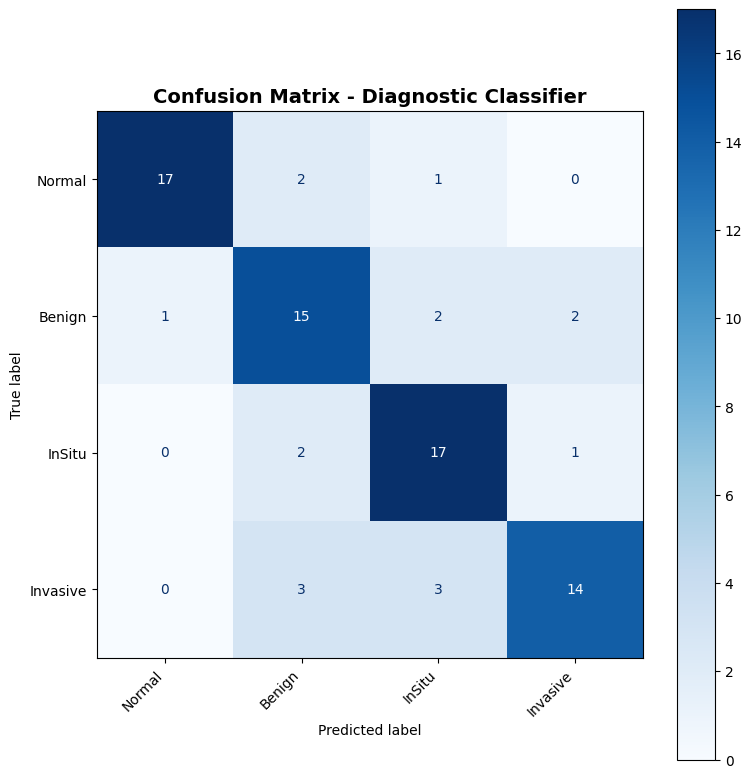

✔️ Confusion matrix plot saved.


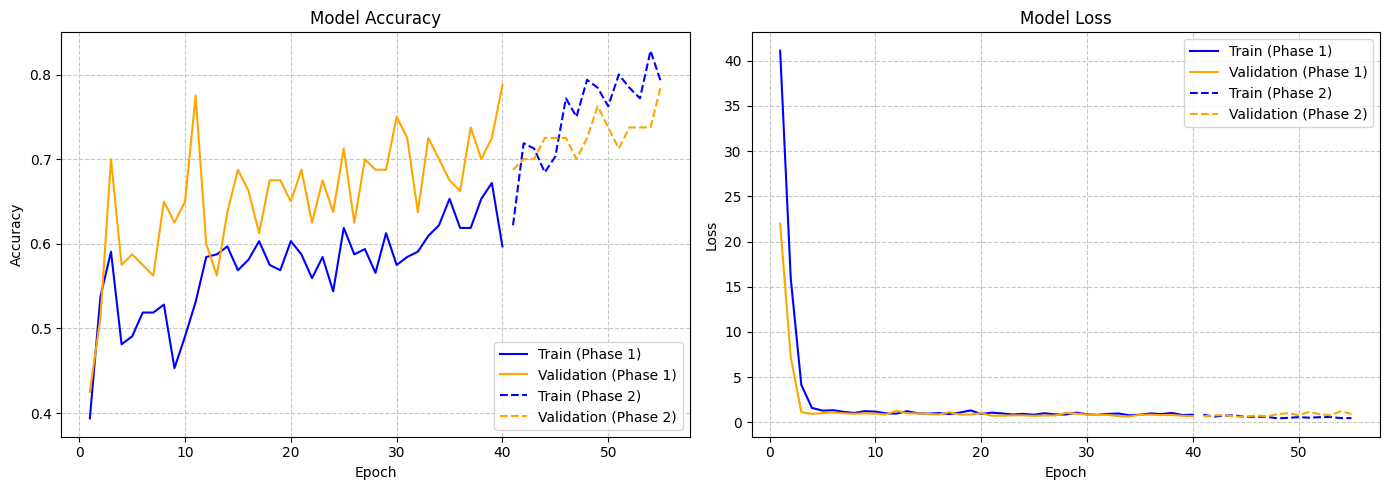

✔️ Training history plot saved.


In [ ]:
# --- 8. EVALUATION & VISUALIZATION ---
print("\n" + "="*50)
print("EVALUATING THE MODEL")
print("="*50)

# Load the best saved model from fine-tuning
final_model = tf.keras.models.load_model(os.path.join(MODEL_DIR, 'classifier_final.h5'))

# Final evaluation on test set
test_loss, test_accuracy = final_model.evaluate(X_test, y_test_cat, verbose=0)
print(f"\n✅ Final Model Test Accuracy: {test_accuracy:.4f}")
print(f"✅ Final Model Test Loss: {test_loss:.4f}")

# Generate predictions for detailed analysis
y_pred_probs = final_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test_cat, axis=1)

# Plot 1: Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix - Diagnostic Classifier', fontweight='bold', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'confusion_matrix.png'), dpi=300, bbox_inches='tight')
plt.show()
print("✔️ Confusion matrix plot saved.")

# Plot 2: Combined Training History
def plot_combined_history(hist1, hist2):
    total_epochs = len(hist1.history['accuracy']) + len(hist2.history['accuracy'])
    epoch_range = range(1, total_epochs + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Plot Accuracy
    ax1.plot(epoch_range[:len(hist1.epoch)], hist1.history['accuracy'], label='Train (Phase 1)', color='blue', linestyle='-')
    ax1.plot(epoch_range[:len(hist1.epoch)], hist1.history['val_accuracy'], label='Validation (Phase 1)', color='orange', linestyle='-')
    ax1.plot(epoch_range[len(hist1.epoch):], hist2.history['accuracy'], label='Train (Phase 2)', color='blue', linestyle='--')
    ax1.plot(epoch_range[len(hist1.epoch):], hist2.history['val_accuracy'], label='Validation (Phase 2)', color='orange', linestyle='--')
    ax1.set_title('Model Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.7)

    # Plot Loss
    ax2.plot(epoch_range[:len(hist1.epoch)], hist1.history['loss'], label='Train (Phase 1)', color='blue', linestyle='-')
    ax2.plot(epoch_range[:len(hist1.epoch)], hist1.history['val_loss'], label='Validation (Phase 1)', color='orange', linestyle='-')
    ax2.plot(epoch_range[len(hist1.epoch):], hist2.history['loss'], label='Train (Phase 2)', color='blue', linestyle='--')
    ax2.plot(epoch_range[len(hist1.epoch):], hist2.history['val_loss'], label='Validation (Phase 2)', color='orange', linestyle='--')
    ax2.set_title('Model Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'training_history.png'), dpi=300, bbox_inches='tight')
    plt.show()

plot_combined_history(history_phase1, history_phase2)
print("✔️ Training history plot saved.")

In [ ]:
#DATA_DIR = "/content/drive/MyDrive/BreastCancerProject/data/processed" # Directory where we saved our NPY files
MODEL_DIR = "/content/drive/MyDrive/BreastCancerProject/models"
RESULTS_DIR = "/content/drive/MyDrive/BreastCancerProject/results/figures"

In [ ]:
# Save a detailed classification report to CSV
report_dict = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose().round(4)
report_df.to_csv(os.path.join('/content/drive/MyDrive/BreastCancerProject/results/figures/classification_report.csv'))
print("📊 Classification Report:")
print(report_df.round(4)) # Print a nicely formatted version to the console

print("\n" + "="*50)
print("NOTEBOOK 2 EXECUTION COMPLETE!")
print("="*50)
print("Next step: Proceed to Notebook 3 for Feature Extraction and Clustering.")
print(f"Models saved in: {MODEL_DIR}")
print(f"Figures saved in: {RESULTS_DIR}")

📊 Classification Report:
              precision  recall  f1-score  support
Normal           0.9444  0.8500    0.8947  20.0000
Benign           0.6818  0.7500    0.7143  20.0000
InSitu           0.7391  0.8500    0.7907  20.0000
Invasive         0.8235  0.7000    0.7568  20.0000
accuracy         0.7875  0.7875    0.7875   0.7875
macro avg        0.7972  0.7875    0.7891  80.0000
weighted avg     0.7972  0.7875    0.7891  80.0000

NOTEBOOK 2 EXECUTION COMPLETE!
Next step: Proceed to Notebook 3 for Feature Extraction and Clustering.
Models saved in: /content/drive/MyDrive/BreastCancerProject/models
Figures saved in: /content/drive/MyDrive/BreastCancerProject/results/figures


**Outputs & Report Ready Materials:**

* classifier_final.h5: The saved best model.

* confusion_matrix.png: Visual of model performance per class.

* training_history.png: Plot of accuracy/loss over epochs.

* classification_report.csv: Detailed precision, recall, f1-score.